<a href="https://colab.research.google.com/github/miriamamin1213-ux/3-Fold/blob/main/HecktorGPT2LoRASHAP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================================
# HECKTOR GPT-2 LoRA
# HPV Status Prediction | Compact Single-Cell Notebook
# ============================================================

# 1. IMPORT LIBRARIES, SET SEEDS AND SELECT DEVICE
import os, random, gdown
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from transformers import GPT2Tokenizer, GPT2Model
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, balanced_accuracy_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)
import torch
import transformers
import peft

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)

!pip uninstall -y torchao


SEED = 42
def seed_everything(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# 2. LOAD HECKTOR EXCEL DATA
DATA_FILE = "HPV2025.xlsx"
if not os.path.exists(DATA_FILE):
    downloaded = gdown.download(
        id="1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv",
        output=DATA_FILE, quiet=False
    )
    if downloaded is None or not os.path.exists(DATA_FILE):
        raise FileNotFoundError("Could not download HPV2025.xlsx.")

df = pd.read_excel(DATA_FILE)
TARGET = "HPV Status"
FEATURES = [
    "Age", "Gender", "Tobacco Consumption", "Alcohol Consumption",
    "Performance Status", "T-stage", "N-stage", "M-stage"
]
missing = [c for c in [TARGET] + FEATURES if c not in df.columns]
if missing:
    raise KeyError(f"Required Excel columns missing: {missing}")

# 3. ROBUSTLY NORMALISE TARGET AND SELECT FEATURES
def normalize_target(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    if s in {"0", "0.0", "negative", "neg", "false", "no"}:
        return 0
    if s in {"1", "1.0", "positive", "pos", "true", "yes"}:
        return 1
    try:
        n = float(s)
        if n in (0, 1):
            return int(n)
    except (ValueError, TypeError):
        pass
    return np.nan

df["HPV_Label"] = df[TARGET].apply(normalize_target)
invalid_count = int(df["HPV_Label"].isna().sum())
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)
df = df[FEATURES + ["HPV_Label"]].copy()

if df.empty:
    raise ValueError("No recognised HPV labels found; check the target column.")
counts = df["HPV_Label"].value_counts().reindex([0, 1], fill_value=0)
if (counts < 2).any():
    raise ValueError(f"Insufficient examples for both HPV classes: {counts.to_dict()}")

print("Dataset:", df.shape, "| Invalid/missing target rows dropped:", invalid_count)
print("HPV classes (0=negative, 1=positive):\n", counts)

# 4. STRATIFIED TRAIN / VALIDATION / TEST SPLIT (65/15/20)
train_val_df, test_df = train_test_split(
    df, test_size=0.20, random_state=SEED, stratify=df["HPV_Label"]
)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.1875, random_state=SEED,
    stratify=train_val_df["HPV_Label"]
)
train_df, val_df, test_df = [x.copy() for x in (train_df, val_df, test_df)]

# 5. IMPUTE MISSING FEATURES USING TRAINING DATA ONLY
fill_values = {}
for col in FEATURES:
    if pd.api.types.is_numeric_dtype(train_df[col]):
        value = train_df[col].median()
        if pd.isna(value):
            value = 0
    else:
        modes = train_df[col].dropna().astype(str).mode()
        value = modes.iloc[0] if not modes.empty else "Unknown"
    fill_values[col] = value
    for split in (train_df, val_df, test_df):
        split[col] = split[col].fillna(value)
        if split[col].dtype == object:
            split[col] = split[col].astype(str).replace(
                {"": "Unknown", "nan": "Unknown", "None": "Unknown"}
            )

y_train = train_df["HPV_Label"].to_numpy(dtype=int)
y_val = val_df["HPV_Label"].to_numpy(dtype=int)
y_test = test_df["HPV_Label"].to_numpy(dtype=int)
for name, y in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name}: n={len(y)}, class counts={np.bincount(y, minlength=2)}")

# 6. CONVERT CLINICAL FEATURES INTO TEXT PROMPTS
def display_value(x):
    if pd.isna(x):
        return "Unknown"
    if isinstance(x, (float, np.floating)) and float(x).is_integer():
        return str(int(x))
    return str(x).strip()

def format_stage(x, prefix):
    value = display_value(x)
    if value == "Unknown" or value.upper().startswith(prefix):
        return value
    try:
        n = float(value)
        if n.is_integer():
            return f"{prefix}{int(n)}"
    except ValueError:
        pass
    return f"{prefix}{value}"

def patient_to_text(row):

    age = display_value(row["Age"])
    gender = display_value(row["Gender"])
    tobacco = display_value(row["Tobacco Consumption"])
    alcohol = display_value(row["Alcohol Consumption"])
    performance = display_value(row["Performance Status"])

    t_stage = format_stage(row["T-stage"], "T")
    n_stage = format_stage(row["N-stage"], "N")
    m_stage = format_stage(row["M-stage"], "M")

    return (
        f"This patient is a {age}-year-old {gender}. "
        f"Tobacco consumption is {tobacco}. "
        f"Alcohol consumption is {alcohol}. "
        f"Performance status is {performance}. "
        f"Tumour stage is {t_stage}. "
        f"Nodal stage is {n_stage}. "
        f"Metastatic stage is {m_stage}. "
        "Predict whether the patient is HPV positive or HPV negative."
    )


train_texts = [patient_to_text(r) for _, r in train_df.iterrows()]
val_texts = [patient_to_text(r) for _, r in val_df.iterrows()]
test_texts = [patient_to_text(r) for _, r in test_df.iterrows()]

# 7. LOAD TOKENIZER AND SET TRAINING PARAMETERS
MODEL_NAME = "openai-community/gpt2"
tokenizer = GPT2Tokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token
lengths = [len(tokenizer.encode(t, add_special_tokens=False)) for t in train_texts]
MAX_LENGTH = min(1024, max(32, int(np.ceil(max(lengths) / 8) * 8)))
BATCH_SIZE, EPOCHS = 64, 500
LEARNING_RATE, WEIGHT_DECAY, DROPOUT = 1e-3, 1e-4, 0.1
print("Max prompt length:", max(lengths), "| MAX_LENGTH:", MAX_LENGTH)
print("Batch size:", BATCH_SIZE, "| Epochs:", EPOCHS)

# 8. BUILD DATASETS AND DATA LOADERS
class HPVTextDataset(Dataset):
    def __init__(self, texts, labels):
        self.items = []
        for text, label in zip(texts, labels):
            enc = tokenizer(
                text, max_length=MAX_LENGTH, padding="max_length",
                truncation=True, return_tensors="pt"
            )
            self.items.append((
                enc["input_ids"].squeeze(0),
                enc["attention_mask"].squeeze(0), int(label)
            ))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        ids, mask, label = self.items[i]
        return {"input_ids": ids, "attention_mask": mask,
                "label": torch.tensor(label, dtype=torch.long)}

train_ds = HPVTextDataset(train_texts, y_train)
val_ds = HPVTextDataset(val_texts, y_val)
test_ds = HPVTextDataset(test_texts, y_test)
loader_args = {
    "batch_size": BATCH_SIZE, "num_workers": 0,
    "pin_memory": torch.cuda.is_available()
}
generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, shuffle=True, generator=generator, **loader_args)
val_loader = DataLoader(val_ds, shuffle=False, **loader_args)
test_loader = DataLoader(test_ds, shuffle=False, **loader_args)


# ============================================================
# 9. INITIALISE GPT-2 CLASSIFIER AND CLASS-WEIGHTED LOSS
#     UPDATED: LoRA integration only
# ============================================================

from peft import LoraConfig, get_peft_model, TaskType


class HPVNetGPT2Text(nn.Module):
    def __init__(self):
        super().__init__()

        # Load the original GPT-2 backbone
        self.gpt2 = GPT2Model.from_pretrained(MODEL_NAME)
        self.gpt2.config.use_cache = False
        self.gpt2.config.pad_token_id = tokenizer.pad_token_id

        # Apply LoRA to GPT-2 attention projections
        lora_config = LoraConfig(
            r=6,
            lora_alpha=12,
            target_modules=["c_attn"],
            lora_dropout=0.0,
            bias="none",
            task_type=TaskType.FEATURE_EXTRACTION
        )

        self.gpt2 = get_peft_model(self.gpt2, lora_config)

        # Keep the original HECKTOR classification head unchanged
        hidden_size = self.gpt2.config.hidden_size
        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden_size),
            nn.Dropout(DROPOUT),
            nn.Linear(hidden_size, 128),
            nn.GELU(),
            nn.Dropout(DROPOUT),
            nn.Linear(128, 2)
        )

    def forward(self, input_ids, attention_mask):
        outputs = self.gpt2(
            input_ids=input_ids,
            attention_mask=attention_mask,
            use_cache=False,
            return_dict=True
        )

        # Keep the original last-token pooling
        hidden_states = outputs.last_hidden_state
        last_positions = attention_mask.sum(dim=1) - 1

        pooled_output = hidden_states[
            torch.arange(
                hidden_states.size(0),
                device=hidden_states.device
            ),
            last_positions
        ]

        return self.classifier(pooled_output)


# Initialise the model
model = HPVNetGPT2Text().to(device)

# Show trainable LoRA parameters in the GPT-2 backbone
model.gpt2.print_trainable_parameters()

# Keep the original HECKTOR class weights
class_counts = np.bincount(y_train, minlength=2)
class_weights = torch.tensor(
    len(y_train) / (2 * np.maximum(class_counts, 1)),
    dtype=torch.float32,
    device=device
)

print(
    "Class weights [negative, positive]:",
    class_weights.detach().cpu().numpy()
)

print(
    "Total trainable parameters (LoRA + classifier):",
    sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )
)


# Keep the original weighted loss
def weighted_loss(logits, labels):
    losses = nn.functional.cross_entropy(
        logits, labels, reduction="none"
    )
    return (losses * class_weights[labels]).mean()


# Optimise only LoRA adapters and the classification head
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("LoRA-enabled HECKTOR model initialised.")

# 10. VALIDATION SCORING AND THRESHOLD SELECTION
def get_scores(loader):
    model.eval()
    scores, labels = [], []
    with torch.no_grad():
        for batch in loader:
            ids, mask = batch["input_ids"].to(device), batch["attention_mask"].to(device)
            logits = model(ids, mask)
            scores.extend(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
            labels.extend(batch["label"].numpy())
    return np.asarray(scores), np.asarray(labels, dtype=int)

def evaluate_loss(loader):
    model.eval()
    total, n_total = 0.0, 0
    with torch.no_grad():
        for b in loader:
            ids, mask = b["input_ids"].to(device), b["attention_mask"].to(device)
            labels = b["label"].to(device)
            loss = weighted_loss(model(ids, mask), labels)
            n = len(labels); total += loss.item() * n; n_total += n
    return total / max(n_total, 1)

def choose_threshold(scores, labels):
    thresholds = np.unique(np.r_[0.0, scores, 1.0])
    values = [(float(t), balanced_accuracy_score(labels, scores >= t)) for t in thresholds]
    return max(values, key=lambda x: (x[1], -abs(x[0] - 0.5)))

# 11. TRAIN MODEL AND SAVE BEST VALIDATION CHECKPOINTS
OUT_DIR = Path("ROC_HECKTOR_GPT2_CLASSIFIER")
OUT_DIR.mkdir(parents=True, exist_ok=True)
paths = {
    "Validation_Loss": OUT_DIR / "best_model_validation_loss.pth",
    "Validation_ROC_AUC": OUT_DIR / "best_model_validation_roc_auc.pth",
    "Validation_PR_AUC": OUT_DIR / "best_model_validation_pr_auc.pth",
    "Validation_Balanced_Accuracy": OUT_DIR / "best_model_validation_balanced_accuracy.pth"
}
best = {
    "Validation_Loss": float("inf"), "Validation_ROC_AUC": -float("inf"),
    "Validation_PR_AUC": -float("inf"), "Validation_Balanced_Accuracy": -float("inf")
}
best_info, history = {}, []

for epoch in range(1, EPOCHS + 1):
    model.train()
    loss_sum, n_sum = 0.0, 0
    for b in train_loader:
        ids, mask = b["input_ids"].to(device), b["attention_mask"].to(device)
        labels = b["label"].to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = weighted_loss(model(ids, mask), labels)
        loss.backward()
        optimizer.step()
        n = len(labels); loss_sum += loss.item() * n; n_sum += n

    train_loss = loss_sum / max(n_sum, 1)
    val_loss = evaluate_loss(val_loader)
    val_scores, val_labels = get_scores(val_loader)
    val_auc = roc_auc_score(val_labels, val_scores)
    val_ap = average_precision_score(val_labels, val_scores)
    threshold, val_ba = choose_threshold(val_scores, val_labels)
    metrics = {
        "Validation_Loss": val_loss, "Validation_ROC_AUC": val_auc,
        "Validation_PR_AUC": val_ap, "Validation_Balanced_Accuracy": val_ba
    }
    history.append({
        "Epoch": epoch, "Train_Loss": train_loss, **metrics,
        "Validation_Threshold": threshold
    })

    for name, value in metrics.items():
        improved = value < best[name] if name == "Validation_Loss" else value > best[name]
        if improved:
            best[name] = float(value)
            best_info[name] = {"epoch": epoch, "value": float(value), "threshold": threshold}
            torch.save(model.state_dict(), paths[name])

    if epoch % 50 == 0:
        print(f"Epoch {epoch}/{EPOCHS} | Train Loss={train_loss:.4f} | "
              f"Val Loss={val_loss:.4f} | ROC-AUC={val_auc:.4f} | "
              f"PR-AUC={val_ap:.4f} | BA={val_ba:.4f} | Threshold={threshold:.4f}")

pd.DataFrame(history).to_csv(OUT_DIR / "training_history.csv", index=False)
pd.DataFrame([
    {"Checkpoint": k, **v, "Path": str(paths[k])} for k, v in best_info.items()
]).to_csv(OUT_DIR / "best_validation_checkpoints.csv", index=False)

# 12. EVALUATE ALL CHECKPOINTS ON HELD-OUT TEST SET
results, predictions_by_model = [], {}
for name, path in paths.items():
    model.load_state_dict(torch.load(path, map_location=device))
    scores, labels = get_scores(test_loader)
    threshold = best_info[name]["threshold"]
    preds = (scores >= threshold).astype(int)
    auc, ap = roc_auc_score(labels, scores), average_precision_score(labels, scores)
    ba = balanced_accuracy_score(labels, preds)
    f1 = f1_score(labels, preds, zero_division=0)
    cm = confusion_matrix(labels, preds, labels=[0, 1])

    print(f"\n=== {name} | Best epoch {best_info[name]['epoch']} | Threshold {threshold:.4f} ===")
    print(classification_report(
        labels, preds, labels=[0, 1],
        target_names=["HPV Negative", "HPV Positive"], digits=4, zero_division=0
    ))
    print("Confusion matrix [[TN, FP], [FN, TP]]:\n", cm)
    print(f"Test ROC-AUC={auc:.4f} | PR-AUC={ap:.4f} | BA={ba:.4f} | F1={f1:.4f}")

    results.append({
        "Dataset": "HECKTOR", "Model": "GPT-2 Classifier with LoRA",
        "Checkpoint_Selected_By": name, "Best_Epoch": best_info[name]["epoch"],
        "Validation_Threshold": threshold, "Test_ROC_AUC": auc,
        "Test_PR_AUC": ap, "Test_Balanced_Accuracy": ba, "Test_F1": f1,
        "TN": cm[0, 0], "FP": cm[0, 1], "FN": cm[1, 0], "TP": cm[1, 1]
    })
    predictions_by_model[name] = (labels, scores, preds, threshold)
    pd.DataFrame({
        "True_Label": labels, "HPV_Positive_Score": scores,
        "Predicted_Label": preds, "Threshold": threshold
    }).to_csv(OUT_DIR / f"test_predictions_{name.lower()}.csv", index=False)

results_df = pd.DataFrame(results)
results_df.to_csv(OUT_DIR / "test_metrics_by_checkpoint.csv", index=False)

# 13. SAVE ROC AND PRECISION-RECALL CURVES
for name, (labels, scores, preds, threshold) in predictions_by_model.items():
    safe = name.lower()
    fpr, tpr, roc_thresholds = roc_curve(labels, scores)
    precision, recall, _ = precision_recall_curve(labels, scores)
    auc, ap = roc_auc_score(labels, scores), average_precision_score(labels, scores)

    pd.DataFrame({"FPR": fpr, "TPR": tpr, "Threshold": roc_thresholds}).to_csv(
        OUT_DIR / f"roc_coordinates_{safe}.csv", index=False
    )
    pd.DataFrame({"Precision": precision, "Recall": recall}).to_csv(
        OUT_DIR / f"pr_coordinates_{safe}.csv", index=False
    )

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"AUC={auc:.3f}")
    plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title(f"HECKTOR ROC — {name}"); plt.legend()
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"roc_{safe}.png", dpi=300, bbox_inches="tight")
    plt.close()

    plt.figure(figsize=(6, 5))
    plt.plot(recall, precision, label=f"AP={ap:.3f}")
    plt.xlabel("Recall"); plt.ylabel("Precision")
    plt.title(f"HECKTOR Precision-Recall — {name}"); plt.legend()
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"pr_{safe}.png", dpi=300, bbox_inches="tight")
    plt.close()

# 14. SAVE SETTINGS AND COMPARISON RESULTS
settings = {
    "Dataset": "HECKTOR", "Model": MODEL_NAME, "Target": "HPV Status",
    "Features": ", ".join(FEATURES), "Number_of_Features": len(FEATURES),
    "Split": "65/15/20 stratified", "Seed": SEED, "Epochs": EPOCHS,
    "Batch_Size": BATCH_SIZE, "Learning_Rate": LEARNING_RATE,
    "Weight_Decay": WEIGHT_DECAY, "Dropout": DROPOUT,
    "Max_Length": MAX_LENGTH, "Optimizer": "AdamW",
    "Class_Weighted_Loss": True, "GPT2_Backbone_Frozen": True,
    "Model_Type": "GPT-2 Classifier with LoRA",
    "LoRA_Rank": 6,
    "LoRA_Alpha": 12,
    "LoRA_Target_Modules": "c_attn",
    "LoRA_Dropout": 0.0,
    "Checkpoint_Selection": "Validation loss, ROC-AUC, PR-AUC, balanced accuracy",
    "Threshold_Selection": "Maximum validation balanced accuracy"
}
pd.DataFrame([settings]).to_csv(OUT_DIR / "settings.csv", index=False)

comparison_file = Path("model_roc_pr_auc_comparison.csv")
comparison = results_df[[
    "Dataset", "Model", "Checkpoint_Selected_By", "Best_Epoch",
    "Test_ROC_AUC", "Test_PR_AUC", "Test_Balanced_Accuracy", "Test_F1"
]]
if comparison_file.exists():
    old = pd.read_csv(comparison_file)
    combined = pd.concat([old, comparison], ignore_index=True, sort=False)
    combined = combined.drop_duplicates(
        subset=["Dataset", "Model", "Checkpoint_Selected_By"], keep="last"
    )
else:
    combined = comparison
combined.to_csv(comparison_file, index=False)

print("\nAll outputs saved to:", OUT_DIR.resolve())
print("Comparison CSV:", comparison_file.resolve())

PyTorch: 2.11.0+cu130
Transformers: 5.22.0
PEFT: 0.21.2
Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0
Device: cuda


Downloading...
From: https://drive.google.com/uc?id=1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv
To: /content/HPV2025.xlsx
100%|██████████| 66.0k/66.0k [00:00<00:00, 84.2MB/s]


Dataset: (588, 9) | Invalid/missing target rows dropped: 138
HPV classes (0=negative, 1=positive):
 HPV_Label
0     58
1    530
Name: count, dtype: int64
Train: n=381, class counts=[ 37 344]
Validation: n=89, class counts=[ 9 80]
Test: n=118, class counts=[ 12 106]


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

... (6 outputs left out)

/usr/local/lib/python3.13/dist-packages/peft/tuners/lora/layer.py:2760: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  warnings.warn(


trainable params: 221,184 || all params: 124,660,992 || trainable%: 0.1774
Class weights [negative, positive]: [5.1486487  0.55377907]
Total trainable parameters (LoRA + classifier): 321410
LoRA-enabled HECKTOR model initialised.


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:900.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 50/500 | Train Loss=0.5195 | Val Loss=0.6997 | ROC-AUC=0.7944 | PR-AUC=0.9744 | BA=0.7875 | Threshold=0.8560
Epoch 100/500 | Train Loss=0.3749 | Val Loss=0.5238 | ROC-AUC=0.7972 | PR-AUC=0.9732 | BA=0.7764 | Threshold=0.5490
Epoch 150/500 | Train Loss=0.4101 | Val Loss=0.5660 | ROC-AUC=0.8000 | PR-AUC=0.9728 | BA=0.7764 | Threshold=0.6037
Epoch 200/500 | Train Loss=0.3471 | Val Loss=0.6023 | ROC-AUC=0.7347 | PR-AUC=0.9638 | BA=0.7063 | Threshold=0.8361
Epoch 250/500 | Train Loss=0.3188 | Val Loss=0.6201 | ROC-AUC=0.7653 | PR-AUC=0.9690 | BA=0.7438 | Threshold=0.9555
Epoch 300/500 | Train Loss=0.3048 | Val Loss=0.8158 | ROC-AUC=0.7306 | PR-AUC=0.9617 | BA=0.7063 | Threshold=0.9687
Epoch 350/500 | Train Loss=0.2906 | Val Loss=1.0841 | ROC-AUC=0.6778 | PR-AUC=0.9534 | BA=0.6632 | Threshold=0.9654
Epoch 400/500 | Train Loss=0.2183 | Val Loss=1.7748 | ROC-AUC=0.6361 | PR-AUC=0.9402 | BA=0.6771 | Threshold=0.8787
Epoch 450/500 | Train Loss=0.1449 | Val Loss=1.1648 | ROC-AUC=0.7694 | PR

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Selected checkpoint: Validation_Balanced_Accuracy
Checkpoint epoch: 2
Validation threshold: 0.468729
Checkpoint path: ROC_HECKTOR_GPT2_CLASSIFIER/best_model_validation_balanced_accuracy.pth
Epoch 2 checkpoint loaded successfully.

Features used for explanations:
['Age', 'Gender', 'Tobacco Consumption', 'Alcohol Consumption', 'Performance Status', 'T-stage', 'N-stage', 'M-stage']
Training explanation matrix: (381, 8)
Test explanation matrix: (118, 8)

========== EPOCH 2 TEST PERFORMANCE ==========
Threshold: 0.468729
Test ROC-AUC: 0.763365
Test PR-AUC: 0.962657

========== RUNNING SHAP ==========


  0%|          | 0/40 [00:00<?, ?it/s]


SHAP feature importance:
            Feature  Mean_Absolute_SHAP
            T-stage            0.000220
            N-stage            0.000124
 Performance Status            0.000108
                Age            0.000073
Tobacco Consumption            0.000073
Alcohol Consumption            0.000051
            M-stage            0.000023
             Gender            0.000008


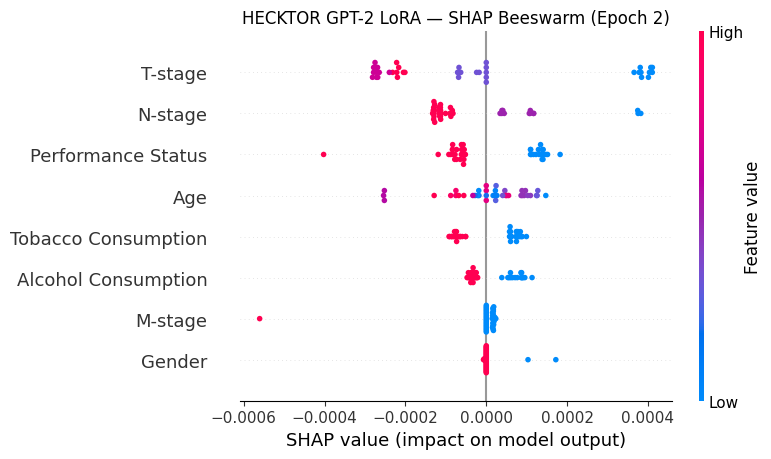

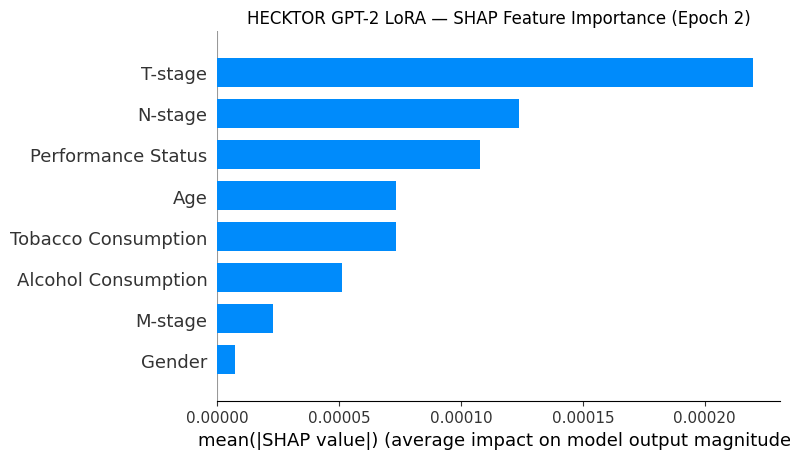


========== RUNNING LIME ==========

LIME explanation for test patient index: 0
True HPV label: 1
Predicted HPV-positive probability: 0.464766

LIME feature contributions:
M-stage=M0: +0.001419
Tobacco Consumption=1.0: -0.000661
Alcohol Consumption=1.0: -0.000556
Performance Status=0.0: +0.000425
N-stage=N1: +0.000217
Age <= 54.00: +0.000168
Gender=1: +0.000111
T-stage=T2: -0.000025


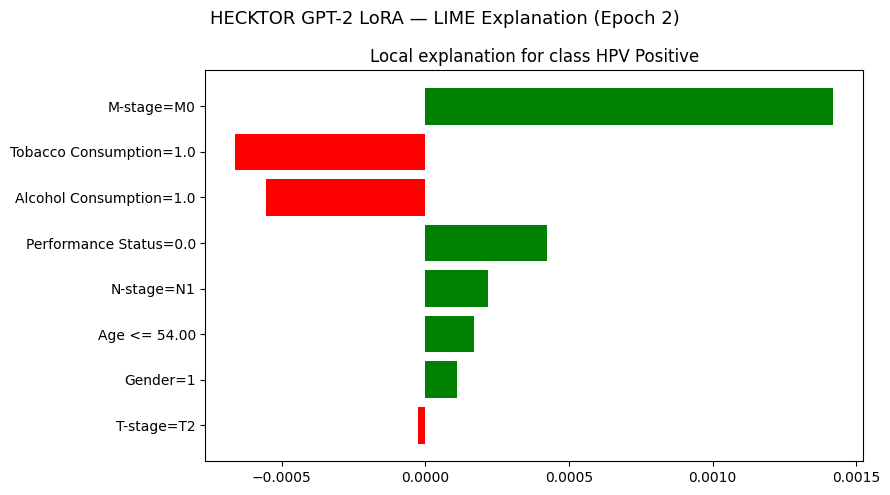


========== EPOCH 2 ROC COORDINATES ==========
ROC-AUC: 0.763365
Number of ROC points: 28

(FPR, TPR, Threshold)
(0.00000000, 0.00000000, inf)
(0.00000000, 0.00943396, 0.46586201)
(0.00000000, 0.16981132, 0.46514305)
(0.08333333, 0.16981132, 0.46514121)
(0.08333333, 0.48113208, 0.46484810)
(0.16666667, 0.48113208, 0.46484244)
(0.16666667, 0.63207547, 0.46468753)
(0.16666667, 0.66037736, 0.46468610)
(0.16666667, 0.66981132, 0.46467996)
(0.25000000, 0.66981132, 0.46465665)
(0.25000000, 0.68867925, 0.46459904)
(0.33333333, 0.68867925, 0.46457100)
(0.33333333, 0.70754717, 0.46456531)
(0.33333333, 0.72641509, 0.46453419)
(0.41666667, 0.72641509, 0.46452487)
(0.41666667, 0.74528302, 0.46448237)
(0.41666667, 0.77358491, 0.46447513)
(0.50000000, 0.77358491, 0.46446314)
(0.50000000, 0.80188679, 0.46440899)
(0.50000000, 0.82075472, 0.46440774)
(0.50000000, 0.85849057, 0.46436319)
(0.58333333, 0.85849057, 0.46436104)
(0.58333333, 0.87735849, 0.46435353)
(0.66666667, 0.87735849, 0.46434736)
(0.666

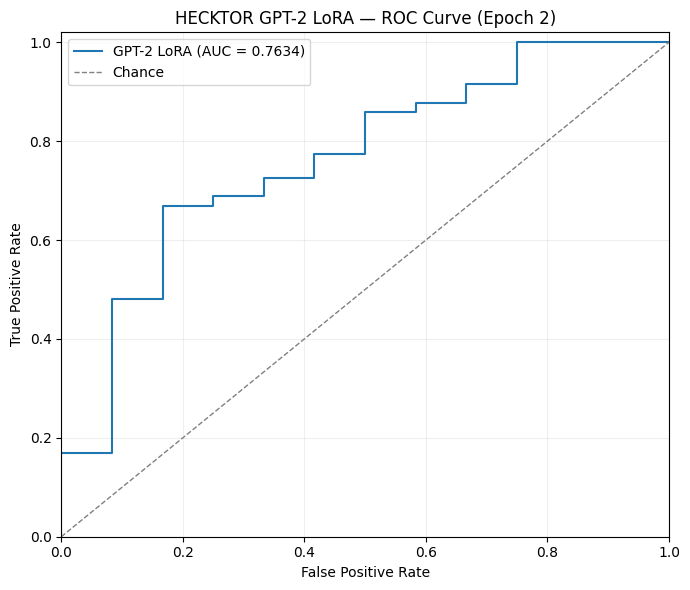


========== EPOCH 2 PRECISION-RECALL COORDINATES ==========
PR-AUC / Average Precision: 0.962657
Number of PR points: 114

(Recall, Precision)
(1.00000000, 0.89830508)
(1.00000000, 0.90598291)
(1.00000000, 0.91379310)
(1.00000000, 0.92173913)
(0.99056604, 0.92105263)
(0.98113208, 0.92035398)
(0.97169811, 0.91964286)
(0.96226415, 0.91891892)
(0.95283019, 0.91818182)
(0.94339623, 0.91743119)
(0.93396226, 0.91666667)
(0.92452830, 0.91588785)
(0.91509434, 0.91509434)
(0.91509434, 0.92380952)
(0.90566038, 0.92307692)
(0.89622642, 0.92233010)
(0.88679245, 0.92156863)
(0.87735849, 0.92079208)
(0.87735849, 0.93000000)
(0.86792453, 0.92929293)
(0.85849057, 0.92857143)
(0.85849057, 0.93814433)
(0.84905660, 0.93750000)
(0.83962264, 0.93684211)
(0.83018868, 0.93617021)
(0.82075472, 0.93548387)
(0.80188679, 0.93406593)
(0.79245283, 0.93333333)
(0.78301887, 0.93258427)
(0.77358491, 0.93181818)
(0.77358491, 0.94252874)
(0.76415094, 0.94186047)
(0.75471698, 0.94117647)
(0.74528302, 0.94047619)
(0.7264

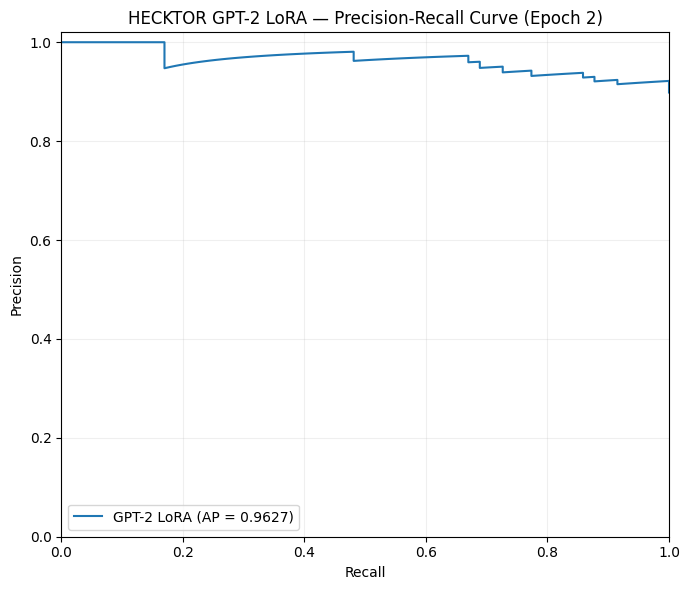


========== SUMMARY ==========
Dataset      Model                   Checkpoint  Best_Epoch  Validation_Threshold  Test_ROC_AUC  Test_PR_AUC  SHAP_Patients_Explained  LIME_Patient_Index  LIME_True_Label  LIME_Predicted_Probability
HECKTOR GPT-2 LoRA Validation_Balanced_Accuracy           2              0.468729      0.763365     0.962657                       40                   0                1                    0.464766

All files saved to:
/content/HECKTOR_GPT2_LORA_EPOCH2_EXPLAINABILITY

ZIP archive created:
/content/HECKTOR_GPT2_LORA_EPOCH2_SHAP_LIME_ROC_PR.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:

# ============================================================
# HECKTOR GPT-2 LoRA — EPOCH 2
# SHAP + LIME + ROC/PR COORDINATES
# Save all plots, explanations and coordinate files
# ============================================================

# 1. INSTALL REQUIRED PACKAGES
!pip -q install shap lime

# 2. IMPORT LIBRARIES
import os
import zipfile
import warnings
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import shap

from lime.lime_tabular import LimeTabularExplainer
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)
from pathlib import Path

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 3. CHECK REQUIRED NOTEBOOK VARIABLES
# ------------------------------------------------------------
required_variables = [
    "model", "device", "train_df", "test_df",
    "FEATURES", "patient_to_text", "tokenizer",
    "MAX_LENGTH", "best_info", "paths"
]

missing = [v for v in required_variables if v not in globals()]

if missing:
    raise RuntimeError(
        "The following notebook variables are missing: "
        + ", ".join(missing)
        + ". Run the original HECKTOR training notebook first."
    )

# ------------------------------------------------------------
# 4. SELECT THE EPOCH 2 CHECKPOINT
# ------------------------------------------------------------
checkpoint_name = "Validation_Balanced_Accuracy"

checkpoint_path = paths[checkpoint_name]
best_epoch = best_info[checkpoint_name]["epoch"]
threshold = float(best_info[checkpoint_name]["threshold"])

print("Selected checkpoint:", checkpoint_name)
print("Checkpoint epoch:", best_epoch)
print("Validation threshold:", round(threshold, 6))
print("Checkpoint path:", checkpoint_path)

if best_epoch != 2:
    raise ValueError(
        f"Expected epoch 2, but the current checkpoint is epoch {best_epoch}. "
        "Check that this is the training run shown in your results."
    )

# Load the epoch 2 LoRA model weights
state_dict = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)
model.load_state_dict(state_dict)
model.to(device)
model.eval()

print("Epoch 2 checkpoint loaded successfully.")

# ------------------------------------------------------------
# 5. OUTPUT DIRECTORY
# ------------------------------------------------------------
OUTPUT_DIR = Path("/content/HECKTOR_GPT2_LORA_EPOCH2_EXPLAINABILITY")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 6. PREPARE THE ORIGINAL EIGHT CLINICAL FEATURES
# ------------------------------------------------------------
FEATURE_NAMES = list(FEATURES)

# Age is treated as continuous.
# The remaining clinical variables are treated as categorical.
CATEGORICAL_FEATURES = [
    feature for feature in FEATURE_NAMES
    if feature != "Age"
]

categorical_indices = [
    FEATURE_NAMES.index(feature)
    for feature in CATEGORICAL_FEATURES
]

def clean_category(value):
    if pd.isna(value):
        return "Unknown"

    value = str(value).strip()

    if value in ["", "nan", "None"]:
        return "Unknown"

    return value


# Construct category mappings using training data only.
category_maps = {}
category_names = {}

for feature in CATEGORICAL_FEATURES:

    values = [
        clean_category(x)
        for x in train_df[feature].tolist()
    ]

    unique_values = sorted(set(values))

    if "Unknown" not in unique_values:
        unique_values.append("Unknown")

    category_maps[feature] = {
        value: index
        for index, value in enumerate(unique_values)
    }

    category_names[FEATURE_NAMES.index(feature)] = unique_values


def encode_dataframe(dataframe):

    encoded = np.zeros(
        (len(dataframe), len(FEATURE_NAMES)),
        dtype=np.float64
    )

    for j, feature in enumerate(FEATURE_NAMES):

        if feature == "Age":

            encoded[:, j] = pd.to_numeric(
                dataframe[feature],
                errors="coerce"
            ).fillna(
                pd.to_numeric(
                    train_df[feature],
                    errors="coerce"
                ).median()
            ).to_numpy(dtype=float)

        else:

            mapping = category_maps[feature]

            encoded[:, j] = [
                mapping.get(clean_category(value),
                            mapping["Unknown"])
                for value in dataframe[feature].tolist()
            ]

    return encoded


def decode_matrix(encoded_matrix):

    encoded_matrix = np.asarray(encoded_matrix)

    if encoded_matrix.ndim == 1:
        encoded_matrix = encoded_matrix.reshape(1, -1)

    decoded_rows = []

    for row in encoded_matrix:

        patient = {}

        for j, feature in enumerate(FEATURE_NAMES):

            value = row[j]

            if feature == "Age":

                patient[feature] = float(value)

            else:

                categories = category_names[j]

                category_index = int(
                    np.clip(
                        np.rint(value),
                        0,
                        len(categories) - 1
                    )
                )

                patient[feature] = categories[category_index]

        decoded_rows.append(patient)

    return pd.DataFrame(decoded_rows, columns=FEATURE_NAMES)


X_train_explain = encode_dataframe(train_df)
X_test_explain = encode_dataframe(test_df)

y_test_explain = test_df["HPV_Label"].to_numpy(dtype=int)

print("\nFeatures used for explanations:")
print(FEATURE_NAMES)

print("Training explanation matrix:", X_train_explain.shape)
print("Test explanation matrix:", X_test_explain.shape)

# ------------------------------------------------------------
# 7. GPT-2 PREDICTION FUNCTION
# ------------------------------------------------------------
def predict_proba_original_features(X):

    """
    Input:
        Matrix containing the original eight clinical features.

    Process:
        Decode categorical values.
        Rebuild the original GPT-2 clinical prompts.
        Tokenize prompts.
        Predict HPV-negative and HPV-positive probabilities.

    Output:
        Array with two columns:
        [HPV-negative probability, HPV-positive probability]
    """

    X = np.asarray(X, dtype=np.float64)

    if X.ndim == 1:
        X = X.reshape(1, -1)

    decoded = decode_matrix(X)

    prompts = [
        patient_to_text(row)
        for _, row in decoded.iterrows()
    ]

    model.eval()

    all_probabilities = []

    batch_size = 16

    for start in range(0, len(prompts), batch_size):

        batch_prompts = prompts[start:start + batch_size]

        tokens = tokenizer(
            batch_prompts,
            max_length=MAX_LENGTH,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        input_ids = tokens["input_ids"].to(device)
        attention_mask = tokens["attention_mask"].to(device)

        with torch.no_grad():

            logits = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            probabilities = torch.softmax(logits, dim=1)

        all_probabilities.append(
            probabilities.cpu().numpy()
        )

    return np.vstack(all_probabilities)


def predict_positive_probability(X):
    return predict_proba_original_features(X)[:, 1]


# ------------------------------------------------------------
# 8. OBTAIN EPOCH 2 TEST PREDICTIONS
# ------------------------------------------------------------
test_probabilities = predict_proba_original_features(
    X_test_explain
)

test_scores = test_probabilities[:, 1]

test_predictions = (
    test_scores >= threshold
).astype(int)

test_roc_auc = roc_auc_score(
    y_test_explain,
    test_scores
)

test_pr_auc = average_precision_score(
    y_test_explain,
    test_scores
)

print("\n========== EPOCH 2 TEST PERFORMANCE ==========")
print("Threshold:", round(threshold, 6))
print("Test ROC-AUC:", round(test_roc_auc, 6))
print("Test PR-AUC:", round(test_pr_auc, 6))

# Save predictions
pd.DataFrame({
    "True_Label": y_test_explain,
    "HPV_Negative_Probability": test_probabilities[:, 0],
    "HPV_Positive_Probability": test_scores,
    "Predicted_Label": test_predictions,
    "Threshold": threshold
}).to_csv(
    OUTPUT_DIR / "epoch2_test_predictions.csv",
    index=False
)

# ------------------------------------------------------------
# 9. SHAP — KERNEL EXPLAINER
# ------------------------------------------------------------
print("\n========== RUNNING SHAP ==========")

# Use a small representative training background.
rng = np.random.default_rng(42)

background_size = min(30, len(X_train_explain))
background_indices = rng.choice(
    len(X_train_explain),
    size=background_size,
    replace=False
)

X_background = X_train_explain[background_indices]

# Explain a subset of test patients to control computation time.
explain_size = min(40, len(X_test_explain))
X_shap = X_test_explain[:explain_size]

explainer = shap.KernelExplainer(
    predict_positive_probability,
    X_background
)

shap_values_raw = explainer.shap_values(
    X_shap,
    nsamples=100
)

# Handle SHAP output formats across SHAP versions.
if isinstance(shap_values_raw, list):

    shap_values_positive = np.asarray(
        shap_values_raw[1]
    )

else:

    shap_values_positive = np.asarray(
        shap_values_raw
    )

    if shap_values_positive.ndim == 3:

        if shap_values_positive.shape[-1] == 2:
            shap_values_positive = shap_values_positive[:, :, 1]

        elif shap_values_positive.shape[0] == 2:
            shap_values_positive = shap_values_positive[1]

if shap_values_positive.shape != X_shap.shape:

    raise ValueError(
        "Unexpected SHAP output shape: "
        f"{shap_values_positive.shape}. "
        f"Expected {X_shap.shape}."
    )

# Save SHAP values
shap_df = pd.DataFrame(
    shap_values_positive,
    columns=FEATURE_NAMES
)

shap_df.to_csv(
    OUTPUT_DIR / "epoch2_shap_values.csv",
    index=False
)

# Save mean absolute SHAP importance
shap_importance = pd.DataFrame({
    "Feature": FEATURE_NAMES,
    "Mean_Absolute_SHAP": np.abs(
        shap_values_positive
    ).mean(axis=0)
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

shap_importance.to_csv(
    OUTPUT_DIR / "epoch2_shap_feature_importance.csv",
    index=False
)

print("\nSHAP feature importance:")
print(shap_importance.to_string(index=False))

# SHAP beeswarm plot
plt.figure()

shap.summary_plot(
    shap_values_positive,
    X_shap,
    feature_names=FEATURE_NAMES,
    show=False,
    max_display=len(FEATURE_NAMES)
)

plt.title(
    "HECKTOR GPT-2 LoRA — SHAP Beeswarm (Epoch 2)"
)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "epoch2_SHAP_beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# SHAP global bar plot
plt.figure()

shap.summary_plot(
    shap_values_positive,
    X_shap,
    feature_names=FEATURE_NAMES,
    plot_type="bar",
    show=False,
    max_display=len(FEATURE_NAMES)
)

plt.title(
    "HECKTOR GPT-2 LoRA — SHAP Feature Importance (Epoch 2)"
)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "epoch2_SHAP_bar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 10. LIME — LOCAL EXPLANATION
# ------------------------------------------------------------
print("\n========== RUNNING LIME ==========")

lime_explainer = LimeTabularExplainer(
    training_data=X_train_explain,
    feature_names=FEATURE_NAMES,
    class_names=["HPV Negative", "HPV Positive"],
    categorical_features=categorical_indices,
    categorical_names=category_names,
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

# Explain the first test patient.
patient_index = 0
patient_to_explain = X_test_explain[patient_index]

lime_explanation = lime_explainer.explain_instance(
    data_row=patient_to_explain,
    predict_fn=predict_proba_original_features,
    num_features=len(FEATURE_NAMES),
    num_samples=2000
)

print("\nLIME explanation for test patient index:", patient_index)
print("True HPV label:", y_test_explain[patient_index])
print("Predicted HPV-positive probability:",
      round(float(test_scores[patient_index]), 6))

print("\nLIME feature contributions:")
for feature, contribution in lime_explanation.as_list():
    print(f"{feature}: {contribution:+.6f}")

# Save LIME explanation as CSV
lime_items = lime_explanation.as_list()

lime_df = pd.DataFrame(
    lime_items,
    columns=["Feature", "LIME_Contribution"]
)

lime_df.to_csv(
    OUTPUT_DIR / "epoch2_LIME_contributions.csv",
    index=False
)

# Save LIME HTML explanation
lime_explanation.save_to_file(
    str(OUTPUT_DIR / "epoch2_LIME_explanation.html")
)

# LIME green/red plot
fig = lime_explanation.as_pyplot_figure(
    label=1
)

fig.set_size_inches(9, 5)
fig.suptitle(
    "HECKTOR GPT-2 LoRA — LIME Explanation (Epoch 2)",
    fontsize=13
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "epoch2_LIME_green_red.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 11. ROC CURVE AND PRINT EVERY ROC COORDINATE
# ------------------------------------------------------------
print("\n========== EPOCH 2 ROC COORDINATES ==========")

fpr, tpr, roc_thresholds = roc_curve(
    y_test_explain,
    test_scores
)

roc_auc_value = roc_auc_score(
    y_test_explain,
    test_scores
)

roc_coordinates = pd.DataFrame({
    "FPR": fpr,
    "TPR": tpr,
    "Threshold": roc_thresholds
})

roc_coordinates.to_csv(
    OUTPUT_DIR / "epoch2_ROC_coordinates.csv",
    index=False
)

print("ROC-AUC:", round(roc_auc_value, 6))
print("Number of ROC points:", len(fpr))
print("\n(FPR, TPR, Threshold)")

for x, y, t in zip(fpr, tpr, roc_thresholds):
    print(f"({x:.8f}, {y:.8f}, {t:.8f})")

# Plot ROC
plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=1.5,
    label=f"GPT-2 LoRA (AUC = {roc_auc_value:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1,
    color="grey",
    label="Chance"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("HECKTOR GPT-2 LoRA — ROC Curve (Epoch 2)")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "epoch2_ROC_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 12. PRECISION-RECALL CURVE AND PRINT EVERY COORDINATE
# ------------------------------------------------------------
print("\n========== EPOCH 2 PRECISION-RECALL COORDINATES ==========")

precision, recall, pr_thresholds = precision_recall_curve(
    y_test_explain,
    test_scores
)

pr_auc_value = average_precision_score(
    y_test_explain,
    test_scores
)

pr_coordinates = pd.DataFrame({
    "Recall": recall,
    "Precision": precision
})

pr_coordinates.to_csv(
    OUTPUT_DIR / "epoch2_PR_coordinates.csv",
    index=False
)

print("PR-AUC / Average Precision:", round(pr_auc_value, 6))
print("Number of PR points:", len(recall))
print("\n(Recall, Precision)")

for x, y in zip(recall, precision):
    print(f"({x:.8f}, {y:.8f})")

# Plot PR curve
plt.figure(figsize=(7, 6))

plt.plot(
    recall,
    precision,
    linewidth=1.5,
    label=f"GPT-2 LoRA (AP = {pr_auc_value:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(
    "HECKTOR GPT-2 LoRA — Precision-Recall Curve (Epoch 2)"
)

plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "epoch2_PR_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 13. SAVE SUMMARY
# ------------------------------------------------------------
summary = pd.DataFrame([{
    "Dataset": "HECKTOR",
    "Model": "GPT-2 LoRA",
    "Checkpoint": checkpoint_name,
    "Best_Epoch": best_epoch,
    "Validation_Threshold": threshold,
    "Test_ROC_AUC": roc_auc_value,
    "Test_PR_AUC": pr_auc_value,
    "SHAP_Patients_Explained": len(X_shap),
    "LIME_Patient_Index": patient_index,
    "LIME_True_Label": int(y_test_explain[patient_index]),
    "LIME_Predicted_Probability": float(test_scores[patient_index])
}])

summary.to_csv(
    OUTPUT_DIR / "epoch2_explainability_summary.csv",
    index=False
)

print("\n========== SUMMARY ==========")
print(summary.to_string(index=False))

# ------------------------------------------------------------
# 14. ZIP ALL OUTPUTS AND DOWNLOAD
# ------------------------------------------------------------
zip_path = Path(
    "/content/HECKTOR_GPT2_LORA_EPOCH2_SHAP_LIME_ROC_PR.zip"
)

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zip_file:

    for file_path in OUTPUT_DIR.rglob("*"):

        if file_path.is_file():

            zip_file.write(
                file_path,
                arcname=file_path.relative_to(OUTPUT_DIR)
            )

print("\nAll files saved to:")
print(OUTPUT_DIR)

print("\nZIP archive created:")
print(zip_path)

# Download all SHAP, LIME, ROC and PR outputs
from google.colab import files
files.download(str(zip_path))
